In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import urllib.request
from google.colab import files

print(f"Current OpenCV Version: {cv2.__version__}")

Current OpenCV Version: 5.0.0


In [3]:
os.makedirs('model/face', exist_ok=True)

YUNET_URL = 'https://github.com/opencv/opencv_zoo/raw/main/models/face_detection_yunet/face_detection_yunet_2023mar.onnx'
SFACE_URL = 'https://github.com/opencv/opencv_zoo/raw/main/models/face_recognition_sface/face_recognition_sface_2021dec.onnx'

YUNET_PATH = 'model/face/face_detection_yunet_2023mar.onnx'
SFACE_PATH = 'model/face/face_recognition_sface_2021dec.onnx'

if not os.path.exists(YUNET_PATH):
  print("Downloading SFace Model...")
  urllib.request.urlretrieve(YUNET_URL, YUNET_PATH)
  print("YuNet Downloaded.")
else:
  print("YuNet Found.")

if not os.path.exists(SFACE_PATH):
  print("Downloading SFace Model...")
  urllib.request.urlretrieve(SFACE_URL, SFACE_PATH)
  print("SFace Downloaded.")
else:
  print("SFace Found.")

YuNet Found.
SFace Found.


Saving LISA-HD-WALLPAPER-4K.jpg to LISA-HD-WALLPAPER-4K (1).jpg

 Reference Image Saved: images/LISA-HD-WALLPAPER-4K (1).jpg


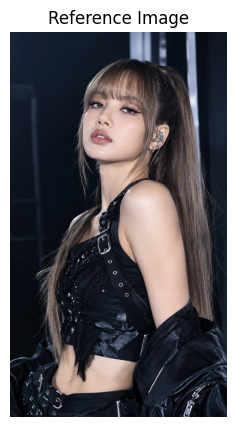

In [5]:
uploaded = files.upload()

os.makedirs('images', exist_ok=True)

ref_path = None
for filename in uploaded.keys():
  ref_path = os.path.join('images', filename)
  os.rename(filename, ref_path)
  print(f"\n Reference Image Saved: {ref_path}")

if ref_path:
  ref_img = cv2.imread(ref_path)
  plt.figure(figsize=(5, 5))
  plt.imshow(cv2.cvtColor(ref_img, cv2.COLOR_BGR2RGB))
  plt.title("Reference Image")
  plt.axis('off')
  plt.show()

Reference Face Feature Extracted Successfully
Feature Shape: (1, 128)


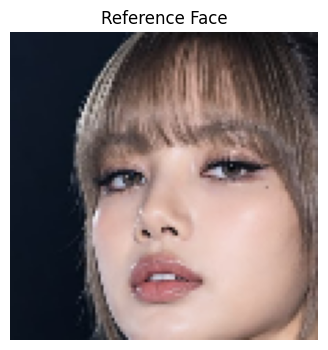

In [6]:
detector = cv2.FaceDetectorYN.create(YUNET_PATH, "", (320, 320), 0.7, 0.3, 5000)
recognizer = cv2.FaceRecognizerSF.create(SFACE_PATH, "")

ref_img = cv2.imread(ref_path)
assert ref_img is not None, "Failed To Load Reference Image"

rh, rw = ref_img.shape[:2]
detector.setInputSize((rw, rh))
ref_faces = detector.detect(ref_img)
assert ref_faces[1] is not None and len(ref_faces[1]) > 0, "No Faces Found In Reference Image"

ref_align = recognizer.alignCrop(ref_img, ref_faces[1][0])
ref_feat = recognizer.feature(ref_align)

COSINE_THRESHOLD = 0.363

print("Reference Face Feature Extracted Successfully")
print(f"Feature Shape: {ref_feat.shape}")

plt.figure(figsize=(4, 4))

plt.imshow(cv2.cvtColor(ref_align, cv2.COLOR_BGR2RGB))
plt.title("Reference Face")
plt.axis('off')

plt.show()

In [7]:
os.makedirs('videos', exist_ok=True)

uploaded = files.upload()

video_path = None
for filename in uploaded.keys():
  video_path = os.path.join('videos', filename)
  os.rename(filename, video_path)
  print(f"\n Video Saved: {video_path}")

Saving gettyimages-2171422895-640_adpp.mp4 to gettyimages-2171422895-640_adpp.mp4

 Video Saved: videos/gettyimages-2171422895-640_adpp.mp4


Processing Video... (Max 120 Frames)

 Processing Complete
 Statistics:
   - Total Frames Processed: 120
   - Match Detections: 103
   - Other Detections: 17
   - Output Saved: face_match_output.mp4


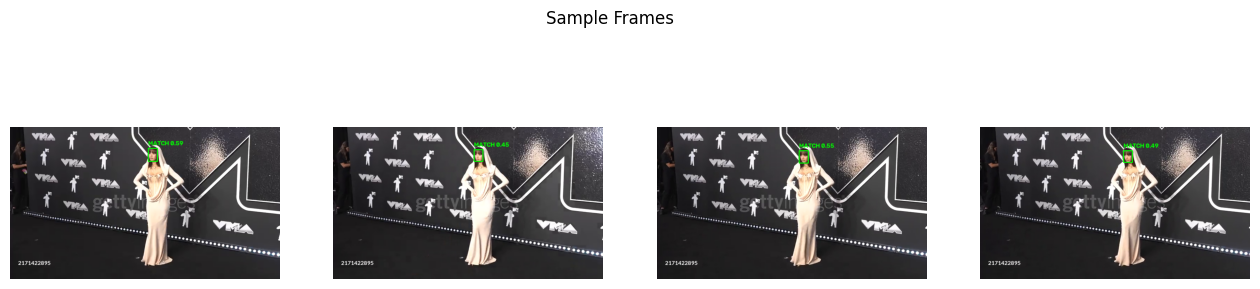

In [9]:
if not video_path or not os.path.exists(video_path):
  print("No Video Found")
else:
  cap = cv2.VideoCapture(video_path)
  fourcc = cv2.VideoWriter_fourcc(*'mp4v')
  out_path = 'face_match_output.mp4'
  fps = cap.get(cv2.CAP_PROP_FPS) or 15
  w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
  h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
  out = cv2.VideoWriter(out_path, fourcc, fps, (w, h))

  samples = []
  idx = 0
  max_frames = 120
  match_count = 0
  other_count = 0

  print(f"Processing Video... (Max {max_frames} Frames)")

  while idx < max_frames:
    ret, frame = cap.read()
    if not ret:
      break

    fh, fw = frame.shape[:2]
    detector.setInputSize((fw, fh))
    faces = detector.detect(frame)
    out_frame = frame.copy()

    if faces[1] is not None:
      for face in faces[1]:
        coords = face[:4].astype(np.int32)
        x, y, fw_face, fh_face = coords[0], coords[1], coords[2], coords[3]

        face_align = recognizer.alignCrop(frame, face)
        feat = recognizer.feature(face_align)

        score = recognizer.match(ref_feat, feat, cv2.FaceRecognizerSF_FR_COSINE)
        is_match = score > COSINE_THRESHOLD

        if is_match:
          match_count += 1
        else:
          other_count += 1

        color = (0, 255, 0) if is_match else (0, 0, 255)
        label = f"MATCH {score:.2f}" if is_match else f"OTHER {score:.2f}"

        cv2.rectangle(out_frame, (x, y), (x + fw_face, y + fh_face), color, 2)
        cv2.putText(out_frame, label, (x, max(0, y - 8)), cv2.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

    out.write(out_frame)
    if idx % 15 == 0:
      samples.append(out_frame.copy())
    idx += 1

  cap.release()
  out.release()

  print(f"\n Processing Complete")
  print(f" Statistics:")
  print(f"   - Total Frames Processed: {idx}")
  print(f"   - Match Detections: {match_count}")
  print(f"   - Other Detections: {other_count}")
  print(f"   - Output Saved: {out_path}")

  n = min(4, len(samples))
  if n > 0:
    plt.figure(figsize=(16, 4))
    for i in range(n):
      plt.subplot(1, n, i + 1)
      plt.imshow(cv2.cvtColor(samples[i], cv2.COLOR_BGR2RGB))
      plt.axis('off')
    plt.suptitle("Sample Frames")
    plt.show()

In [10]:
if os.path.exists('face_match_output.mp4'):
  files.download('face_match_output.mp4')
  print("Output Video Downloaded Successfully.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Output Video Downloaded Successfully.
